# Analysis
## 05 – Integralrechnung: Einführung

**Voraussetzungen:** [02_Ableitungen_Einfuehrung](02_Ableitungen_Einfuehrung.ipynb), [03_Ableitungsregeln](03_Ableitungsregeln.ipynb)

---

### Lernziele

Nach diesem Abschnitt kannst du:

- Erklären, was eine **Stammfunktion** ist und wie sie mit der Ableitung zusammenhängt
- Das **unbestimmte Integral** berechnen und die Integrationskonstante begründen
- Das **bestimmte Integral** als Fläche unter einer Kurve interpretieren
- Den **Hauptsatz der Differential- und Integralrechnung** anwenden
- **Riemann-Summen** als Motivation für das Integral beschreiben

### 1. Von der Ableitung zurück: Die Stammfunktion

Bei der Ableitung fragten wir: *Gegeben $f(x)$, was ist $f'(x)$?*

Jetzt kehren wir die Frage um:

> **Stammfunktion:** $F(x)$ heißt Stammfunktion von $f(x)$, wenn $F'(x) = f(x)$.

**Beispiel:**
- $f(x) = 2x \quad\Rightarrow\quad F(x) = x^2 + C$
- Denn: $(x^2 + C)' = 2x$ ✓

**Warum $+C$?** Jede Konstante verschwindet beim Ableiten. Deshalb hat jede Funktion **unendlich viele** Stammfunktionen - sie unterscheiden sich nur um eine Konstante.

$$F_1(x) = x^2, \quad F_2(x) = x^2 + 5, \quad F_3(x) = x^2 - 3 \quad \text{alle sind Stammfunktionen von } 2x$$

---

### Das unbestimmte Integral

Die Schreibweise für „finde die Stammfunktion von $f(x)$“ ist:
$$\int f(x) \, dx = F(x) + C$$

| Symbol | Bedeutung |
|---|---|
| $f(x)$ | Integrand |
| $dx$ | Integrationsvariable |
| $F(x)$ | Stammfunktion |
| $C$ | Integrationskonstante |

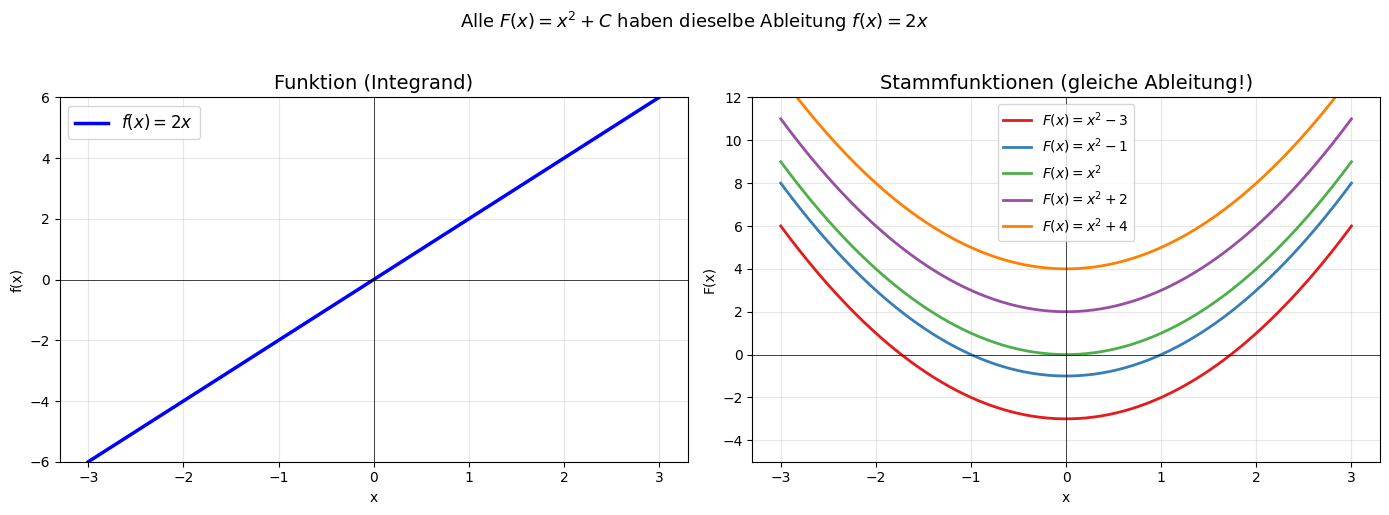

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# --- Stammfunktionen visualisieren ---

def visualisiere_stammfunktionen():
    """Zeigt f(x)=2x und mehrere Stammfunktionen F(x)=x²+C."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.linspace(-3, 3, 300)
    
    # --- Links: Die Funktion f(x) = 2x ---
    ax = axes[0]
    ax.plot(x, 2*x, 'b-', linewidth=2.5, label=r"$f(x) = 2x$")
    ax.set_title("Funktion (Integrand)", fontsize=14)
    ax.legend(fontsize=12)
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.set_ylim(-6, 6)
    
    # --- Rechts: Stammfunktionen F(x) = x² + C ---
    ax = axes[1]
    farben = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3', '#ff7f00']
    C_werte = [-3, -1, 0, 2, 4]
    for C, farbe in zip(C_werte, farben):
        label = f"$F(x) = x^2 {'+' if C >= 0 else '-'} {abs(C)}$" if C != 0 else r"$F(x) = x^2$"
        ax.plot(x, x**2 + C, color=farbe, linewidth=2, label=label)
    ax.set_title("Stammfunktionen (gleiche Ableitung!)", fontsize=14)
    ax.legend(fontsize=10, loc='upper center')
    ax.grid(True, alpha=0.3)
    ax.axhline(0, color='black', linewidth=0.5)
    ax.axvline(0, color='black', linewidth=0.5)
    ax.set_xlabel("x")
    ax.set_ylabel("F(x)")
    ax.set_ylim(-5, 12)
    
    plt.suptitle(r"Alle $F(x) = x^2 + C$ haben dieselbe Ableitung $f(x) = 2x$", 
                 fontsize=13, y=1.02)
    plt.tight_layout()
    plt.show()

visualisiere_stammfunktionen()

### 2. Das bestimmte Integral: Fläche unter der Kurve

Während das unbestimmte Integral eine **Funktionsfamilie** liefert, berechnet das bestimmte Integral eine **Zahl** - die Fläche zwischen $f(x)$ und der $x$-Achse:

$$\int_a^b f(x)\, dx = \text{"Fläche unter } f(x) \text{ von } a \text{ bis } b\text{"}$$

**Wichtig:**
- Fläche **über** der $x$-Achse zählt **positiv**
- Fläche **unter** der $x$-Achse zählt **negativ** (orientierte Fläche)
- Für den tatsächlichen Flächeninhalt: $\displaystyle\int_a^b |f(x)|\, dx$

---

### Riemann-Summen: Die Idee dahinter

Wie berechnet man die Fläche unter einer Kurve? 
Riemann-Summen sind eine Methode, um das Integral zu approximieren:

1. Teile $[a,b]$ in $n$ gleich breite Streifen der Breite $\Delta x = \frac{b-a}{n}$
2. Wähle in jedem Streifen eine Höhe $f(x_i)$
3. Summiere: $\displaystyle S_n = \sum_{i=1}^{n} f(x_i) \cdot \Delta x$

Für $n \to \infty$ konvergiert die Summe zum exakten Integral:

$$\int_a^b f(x)\, dx = \lim_{n \to \infty} \sum_{i=1}^{n} f(x_i) \cdot \Delta x$$

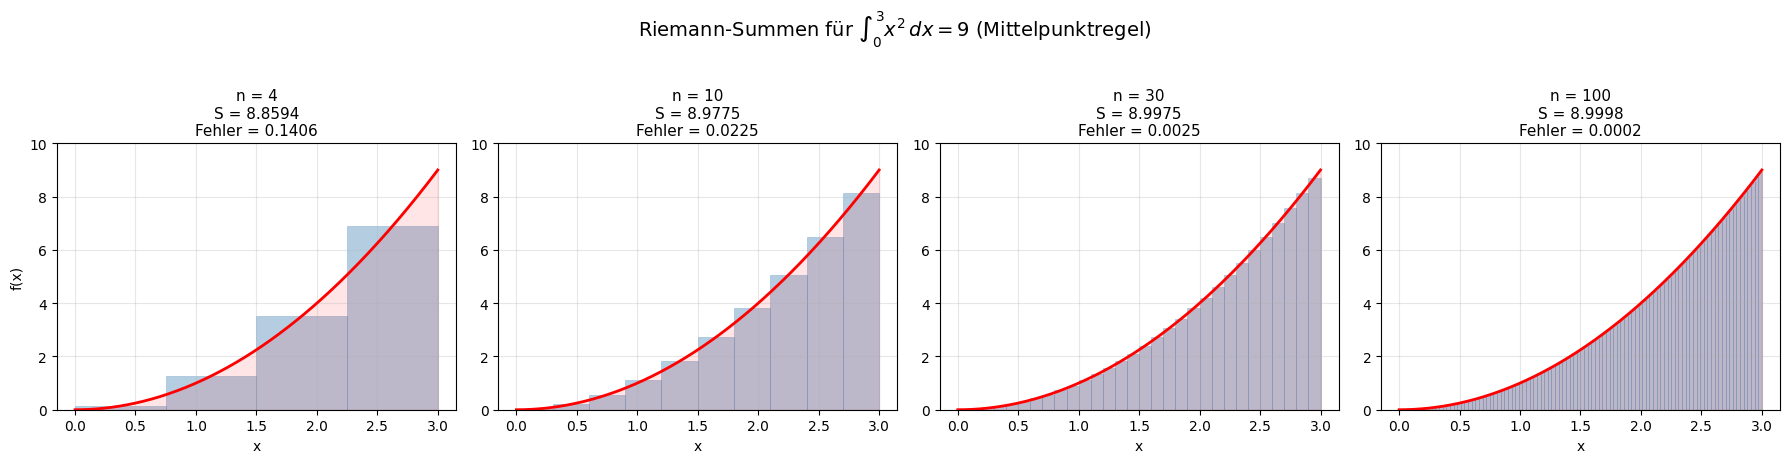

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# --- Riemann-Summen: Konvergenz zum Integral ---

def visualisiere_riemann_integral():
    """Zeigt Riemann-Summen mit steigender Rechteckanzahl + Flächeninterpretation."""
    
    def f(x):
        return x**2
    
    a, b = 0, 3
    exakt = 9.0  # ∫₀³ x² dx = 9
    
    n_werte = [4, 10, 30, 100]
    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
    x_kurve = np.linspace(a, b, 300)
    
    for ax, n in zip(axes, n_werte):
        dx = (b - a) / n
        x_links = np.linspace(a, b - dx, n)
        hoehen = f(x_links + dx/2)  # Mittelpunktregel
        summe = np.sum(hoehen * dx)
        fehler = abs(summe - exakt)
        
        # Rechtecke zeichnen
        ax.bar(x_links, hoehen, width=dx, align='edge', alpha=0.4, 
               color='steelblue', edgecolor='steelblue', linewidth=0.5)
        # Kurve
        ax.plot(x_kurve, f(x_kurve), 'r-', linewidth=2)
        ax.fill_between(x_kurve, f(x_kurve), alpha=0.1, color='red')
        
        ax.set_title(f"n = {n}\nS = {summe:.4f}\nFehler = {fehler:.4f}", fontsize=11)
        ax.set_xlabel("x")
        ax.set_ylim(0, 10)
        ax.grid(True, alpha=0.3)
    
    axes[0].set_ylabel("f(x)")
    plt.suptitle(r"Riemann-Summen für $\int_0^3 x^2\, dx = 9$ (Mittelpunktregel)", 
                 fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

visualisiere_riemann_integral()

### 3. Der Hauptsatz der Differential- und Integralrechnung

Der **Hauptsatz** verbindet Ableitung und Integral - er ist *das* zentrale Ergebnis der Analysis:

> **Hauptsatz (HDI):** Ist $F$ eine Stammfunktion von $f$, dann gilt:
>
> $$\int_a^b f(x)\, dx = F(b) - F(a) = \bigl[F(x)\bigr]_a^b$$

**Das bedeutet:** Um eine Fläche zu berechnen, ist keine Riemann-Summe erforderlich - es genügt die Stammfunktion zu bestimmen!

**Beispiel:**

$$\int_0^3 x^2\, dx = \left[\frac{x^3}{3}\right]_0^3 = \frac{27}{3} - \frac{0}{3} = 9$$

**Schritt für Schritt:**
1. Finde Stammfunktion: $F(x) = \frac{x^3}{3}$
2. Setze obere Grenze ein: $F(3) = 9$
3. Setze untere Grenze ein: $F(0) = 0$
4. Differenz: $F(3) - F(0) = 9$

---

### Was der Hauptsatz *wirklich* sagt

| Richtung | Aussage |
|----------|----------|
| **Integrieren hebt Ableiten auf** | $\displaystyle\int_a^b F'(x)\, dx = F(b) - F(a)$ |
| **Ableiten hebt Integrieren auf** | $\displaystyle\frac{d}{dx}\left(\int_a^x f(t)\, dt\right) = f(x)$ |

> *Hinweis:* Ableitung und Integration sind **Umkehroperationen** - wie Addition/Subtraktion oder Multiplikation/Division.

=== Bestimmte Integrale mit SymPy ===
∫₀³ x² dx  = 9
∫₁⁴ 2x dx  = 15
∫₀π sin(x) dx = 2

=== Unbestimmte Integrale ===
∫ x² dx     = x**3/3  + C
∫ sin(x) dx = -cos(x)  + C
∫ eˣ dx     = exp(x)  + C


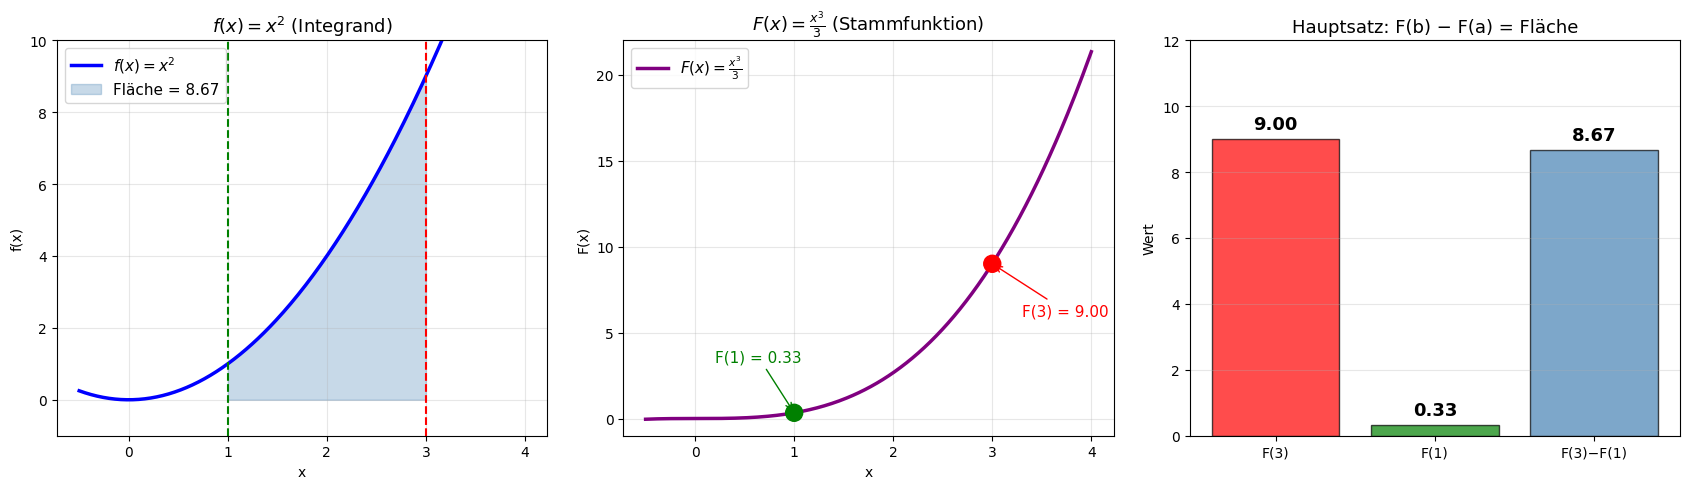

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

# --- Hauptsatz visualisieren ---

def visualisiere_hauptsatz():
    """Zeigt den Zusammenhang f → F → [F(b)-F(a)] = Fläche."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    x = np.linspace(-0.5, 4, 300)
    a, b = 1, 3
    
    # Funktion und Stammfunktion
    f = lambda t: t**2
    F = lambda t: t**3 / 3
    
    # --- Links: f(x) mit Fläche ---
    ax = axes[0]
    ax.plot(x, f(x), 'b-', linewidth=2.5, label=r"$f(x) = x^2$")
    x_fill = np.linspace(a, b, 200)
    ax.fill_between(x_fill, f(x_fill), alpha=0.3, color='steelblue',
                    label=f"Fläche = {F(b)-F(a):.2f}")
    ax.axvline(a, color='green', linestyle='--', linewidth=1.5)
    ax.axvline(b, color='red', linestyle='--', linewidth=1.5)
    ax.set_title(r"$f(x) = x^2$ (Integrand)", fontsize=13)
    ax.legend(fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True, alpha=0.3)
    ax.set_ylim(-1, 10)
    
    # --- Mitte: F(x) mit F(a) und F(b) ---
    ax = axes[1]
    ax.plot(x, F(x), 'purple', linewidth=2.5, label=r"$F(x) = \frac{x^3}{3}$")
    ax.scatter([a, b], [F(a), F(b)], color=['green', 'red'], s=150, zorder=5)
    ax.annotate(f"F({a}) = {F(a):.2f}", xy=(a, F(a)), xytext=(a-0.8, F(a)+3),
                fontsize=11, arrowprops=dict(arrowstyle='->', color='green'), color='green')
    ax.annotate(f"F({b}) = {F(b):.2f}", xy=(b, F(b)), xytext=(b+0.3, F(b)-3),
                fontsize=11, arrowprops=dict(arrowstyle='->', color='red'), color='red')
    ax.set_title(r"$F(x) = \frac{x^3}{3}$ (Stammfunktion)", fontsize=13)
    ax.legend(fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel("F(x)")
    ax.grid(True, alpha=0.3)
    ax.set_ylim(-1, 22)
    
    # --- Rechts: Zusammenfassung als Balkendiagramm ---
    ax = axes[2]
    balken = ax.bar(['F(3)', 'F(1)', 'F(3)−F(1)'], [F(b), F(a), F(b)-F(a)],
                    color=['red', 'green', 'steelblue'], alpha=0.7, edgecolor='black')
    for bar_obj, val in zip(balken, [F(b), F(a), F(b)-F(a)]):
        ax.text(bar_obj.get_x() + bar_obj.get_width()/2, val + 0.3, 
                f"{val:.2f}", ha='center', fontsize=13, fontweight='bold')
    ax.set_title("Hauptsatz: F(b) − F(a) = Fläche", fontsize=13)
    ax.set_ylabel("Wert")
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 12)
    
    plt.tight_layout()
    plt.show()

# --- SymPy Bestätigung ---
x = sp.Symbol('x')

print("=== Bestimmte Integrale mit SymPy ===")
print(f"∫₀³ x² dx  = {sp.integrate(x**2, (x, 0, 3))}")
print(f"∫₁⁴ 2x dx  = {sp.integrate(2*x, (x, 1, 4))}")
print(f"∫₀π sin(x) dx = {sp.integrate(sp.sin(x), (x, 0, sp.pi))}")

print("\n=== Unbestimmte Integrale ===")
print(f"∫ x² dx     = {sp.integrate(x**2, x)}  + C")
print(f"∫ sin(x) dx = {sp.integrate(sp.sin(x), x)}  + C")
print(f"∫ eˣ dx     = {sp.integrate(sp.exp(x), x)}  + C")

visualisiere_hauptsatz()

### 4. Grundintegrale - Die wichtigsten Stammfunktionen

Diese Tabelle ist grundlegend und sollte verinnerlicht werden (sie ergibt sich durch Umkehrung der Ableitungsregeln):

| $f(x)$ | $\int f(x)\, dx$ | Bedingung |
|---------|-------------------|----------|
| $x^n$ | $\dfrac{x^{n+1}}{n+1} + C$ | $n \ne -1$ |
| $\dfrac{1}{x}$ | $\ln\lvert x\rvert + C$ | $x \ne 0$ |
| $e^x$ | $e^x + C$ | |
| $a^x$ | $\dfrac{a^x}{\ln a} + C$ | $a > 0, a \ne 1$ |
| $\sin x$ | $-\cos x + C$ | |
| $\cos x$ | $\sin x + C$ | |
| $\dfrac{1}{\cos^2 x}$ | $\tan x + C$ | |

**Und die linearen Regeln:**

$$\int [f(x) \pm g(x)]\, dx = \int f(x)\, dx \pm \int g(x)\, dx$$

$$\int c \cdot f(x)\, dx = c \cdot \int f(x)\, dx$$

> *Hinweis:* Für Produkt und Quotient gibt es **keine** einfache Regel wie beim Ableiten - dafür braucht man Substitution und partielle Integration (→ nächstes Notebook).

### 5. Fläche unter und über der x-Achse

**Vorsicht:** Das bestimmte Integral kann **negativ** werden!

$$\int_0^\pi \sin x\, dx = 2 \qquad \text{(positiv - Fläche über x-Achse)}$$

$$\int_\pi^{2\pi} \sin x\, dx = -2 \qquad \text{(negativ - Fläche unter x-Achse)}$$

$$\int_0^{2\pi} \sin x\, dx = 0 \qquad \text{(Flächen heben sich auf!)}$$

**Gesamtfläche** (immer positiv):

$$A = \int_0^{2\pi} |\sin x|\, dx = 4$$

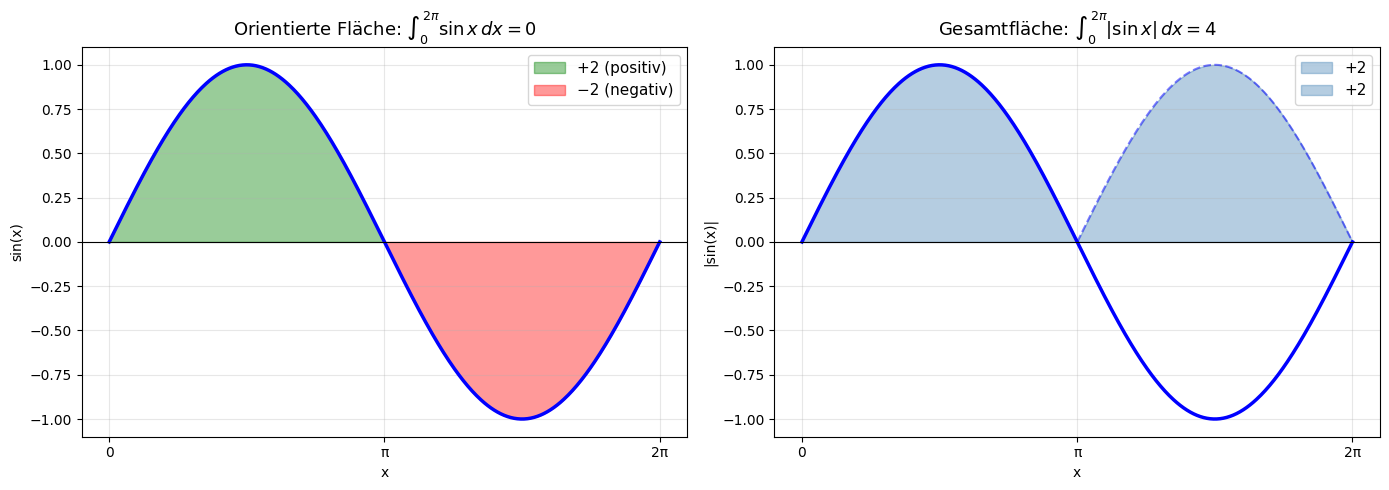

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# --- Positiv/Negativ-Flächen visualisieren ---

def visualisiere_orientierte_flaeche():
    """Zeigt den Unterschied zwischen orientierter Fläche (Integral) und Gesamtfläche."""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    x = np.linspace(0, 2*np.pi, 500)
    y = np.sin(x)
    
    # --- Links: Orientierte Fläche (Integral) ---
    ax = axes[0]
    ax.plot(x, y, 'b-', linewidth=2.5)
    x_pos = np.linspace(0, np.pi, 300)
    x_neg = np.linspace(np.pi, 2*np.pi, 300)
    ax.fill_between(x_pos, np.sin(x_pos), alpha=0.4, color='green', label="+2 (positiv)")
    ax.fill_between(x_neg, np.sin(x_neg), alpha=0.4, color='red', label="−2 (negativ)")
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(r"Orientierte Fläche: $\int_0^{2\pi} \sin x\, dx = 0$", fontsize=13)
    ax.legend(fontsize=11)
    ax.set_xlabel("x")
    ax.set_ylabel("sin(x)")
    ax.grid(True, alpha=0.3)
    ax.set_xticks([0, np.pi, 2*np.pi])
    ax.set_xticklabels(['0', 'π', '2π'])
    
    # --- Rechts: Gesamtfläche |f(x)| ---
    ax = axes[1]
    ax.plot(x, y, 'b-', linewidth=2.5)
    ax.fill_between(x_pos, np.sin(x_pos), alpha=0.4, color='steelblue', label="+2")
    ax.fill_between(x_neg, 0, -np.sin(x_neg), alpha=0.4, color='steelblue', label="+2")
    ax.plot(x_neg, -np.sin(x_neg), 'b--', linewidth=1.5, alpha=0.5)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_title(r"Gesamtfläche: $\int_0^{2\pi} |\sin x|\, dx = 4$", fontsize=13)
    ax.legend(fontsize=11, loc='upper right')
    ax.set_xlabel("x")
    ax.set_ylabel("|sin(x)|")
    ax.grid(True, alpha=0.3)
    ax.set_xticks([0, np.pi, 2*np.pi])
    ax.set_xticklabels(['0', 'π', '2π'])
    
    plt.tight_layout()
    plt.show()

visualisiere_orientierte_flaeche()

---

## Verständnis-Check

*Löse die folgenden Aufgaben eigenständig, bevor du die Lösungen konsultierst.*

**Aufgabe 1:** Bestimme die Stammfunktion: $\int (3x^2 + 2x - 5)\, dx$

**Aufgabe 2:** Berechne das bestimmte Integral: $\displaystyle\int_1^4 \sqrt{x}\, dx = \int_1^4 x^{1/2}\, dx$

**Aufgabe 3:** Berechne: $\displaystyle\int_0^1 (e^x + 1)\, dx$

**Aufgabe 4:** Die Funktion $f(x) = x^2 - 4$ hat Nullstellen bei $x = \pm 2$. Berechne:
- a) $\displaystyle\int_0^3 f(x)\, dx$ (orientierte Fläche)
- b) Die tatsächliche Fläche zwischen $f(x)$ und der $x$-Achse auf $[0, 3]$

**Aufgabe 5:** Erkläre in eigenen Worten, warum die Integrationskonstante $C$ beim bestimmten Integral verschwindet.

### Lösungen

<details>
<summary>Lösung Aufgabe 1</summary>

$$\int (3x^2 + 2x - 5)\, dx = x^3 + x^2 - 5x + C$$

Probe: $(x^3 + x^2 - 5x + C)' = 3x^2 + 2x - 5$ ✓
</details>

<details>
<summary>Lösung Aufgabe 2</summary>

$$\int_1^4 x^{1/2}\, dx = \left[\frac{x^{3/2}}{3/2}\right]_1^4 = \left[\frac{2}{3}x^{3/2}\right]_1^4$$

$$= \frac{2}{3}(4^{3/2}) - \frac{2}{3}(1^{3/2}) = \frac{2}{3}(8) - \frac{2}{3}(1) = \frac{16}{3} - \frac{2}{3} = \frac{14}{3} \approx 4.67$$
</details>

<details>
<summary>Lösung Aufgabe 3</summary>

$$\int_0^1 (e^x + 1)\, dx = \left[e^x + x\right]_0^1 = (e^1 + 1) - (e^0 + 0) = e + 1 - 1 = e \approx 2.718$$
</details>

<details>
<summary>Lösung Aufgabe 4</summary>

a) Orientiert: $\displaystyle\int_0^3 (x^2 - 4)\, dx = \left[\frac{x^3}{3} - 4x\right]_0^3 = (9 - 12) - 0 = -3$

b) Nullstelle bei $x = 2$, also aufteilen:

$$A = \int_0^2 |x^2 - 4|\, dx + \int_2^3 |x^2 - 4|\, dx$$
$$= -\int_0^2 (x^2 - 4)\, dx + \int_2^3 (x^2 - 4)\, dx$$
$$= -\left[\frac{x^3}{3} - 4x\right]_0^2 + \left[\frac{x^3}{3} - 4x\right]_2^3$$
$$= -\left(\frac{8}{3} - 8\right) + \left(-3 - \left(\frac{8}{3}-8\right)\right) = \frac{16}{3} + \frac{7}{3} = \frac{23}{3} \approx 7.67$$
</details>

<details>
<summary>Lösung Aufgabe 5</summary>

Beim bestimmten Integral berechnet man $F(b) - F(a)$. Wenn $F(x) = G(x) + C$:

$$F(b) - F(a) = [G(b) + C] - [G(a) + C] = G(b) - G(a)$$

Die Konstante $C$ hebt sich bei der Subtraktion immer auf → das Ergebnis ist unabhängig von $C$.
</details>

---

## Zusammenfassung

| Konzept | Formel / Idee |
|---------|---------------|
| **Stammfunktion** | $F'(x) = f(x)$ - Umkehrung der Ableitung |
| **Unbestimmtes Integral** | $\int f(x)\, dx = F(x) + C$ |
| **Bestimmtes Integral** | $\int_a^b f(x)\, dx = F(b) - F(a)$ |
| **Riemann-Summe** | Approximation durch $n$ Rechtecke → Grenzwert |
| **Hauptsatz** | Verbindet Ableitung ↔ Integral |
| **Orientierte Fläche** | Unter x-Achse zählt negativ |

> **Nächster Schritt:** Wie löst man kompliziertere Integrale? → Weiter zu **06_Integrationsregeln_Anwendungen**

---

## Glossar

| Deutsch | Englisch |
|---------|----------|
| Stammfunktion | Antiderivative |
| Integrand | Integrand |
| Integrationskonstante | Constant of integration |
| Bestimmtes Integral | Definite integral |
| Unbestimmtes Integral | Indefinite integral |
| Riemann-Summe | Riemann sum |
| Hauptsatz | Fundamental Theorem of Calculus |
| Obere / Untere Grenze | Upper / Lower bound |
| Orientierte Fläche | Signed area |